# Band Subset Degradation — Results

Loads test mIoU for each encoder × dataset × band-level combination.

**Datasets:** MADOS · PASTIS · Sen1Floods11  
**Band progression (optical-only, no padding):**

| n_bands | Level | Bands added |
|---------|-------|-------------|
| 3 | RGB | B2, B3, B4 |
| 4 | +NIR | + B8 |
| 8 | +RedEdge | + B5, B6, B7, B8A |
| 10 | +SWIR | + B11, B12 — also = PASTIS full-optical |
| 11 | Full | + B1 (MADOS only: coastal aerosol) |
| 13 | Full | + B1, B9, B10 (Sen1Floods11 only: adds water vapour + cirrus) |

**RGB endpoints:** reused from `pangaea_rgb/upernet/`  
**New intermediate + full runs:** loaded from `band_subset_degradation/upernet/`

In [1]:
import re
import yaml
from pathlib import Path

import pandas as pd
import numpy as np

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")

# ── Display name mappings ────────────────────────────────────────────────────
ENCODER_LABELS = {
    "carl_no_internal_norm": "CARL",
    "carl_imagewise":        "CARL-Imagewise",
    "carl":                  "CARL",
    "dofa":                  "DOFA",
    "dofav2":                "DOFA+",
    "panopticon":            "Panopticon",
    "copernicus_fm_base":    "Copernicus-FM",
    "smarties_vitb":         "SMARTIES",
    "dinov2_vitb14":         "DINOv2",
    "unet_encoder":          "UNet",
    "vit_scratch":           "ViT-p16",
    "vit_scratch_p8":        "ViT-p8",
}

DATASET_LABELS = {
    "mados":       "MADOS",
    "pastis":      "PASTIS",
    "sen1floods11": "Sen1Floods11",
}

# Ordered band levels for consistent x-axis in plots
BAND_LEVEL_ORDER = [
    "RGB (3)",
    "+NIR (4)",
    "+RedEdge (8)",
    "+SWIR (10)",
    "Full (10)",   # PASTIS — 10 bands IS the optical full
    "Full (11)",   # MADOS — adds B1 coastal aerosol
    "Full (13)",   # Sen1Floods11 — adds B1, B9, B10
]

# Encoder display order for tables and plots
ENCODER_ORDER = [
    "DOFA", "DOFA+", "CARL", "Panopticon", "SMARTIES", "Copernicus-FM",
    "DINOv2",
    "ViT-p8", "ViT-p16", "UNet",
]

# Separate label for frozen vs finetuned ViT (keyed by experiment subfolder name)
FOLDER_ENCODER_LABELS = {
    "dofa_band_degradation":             "DOFA",
    "dofav2_band_degradation":           "DOFA+",
    "carl_band_degradation":             "CARL",
    "panopticon_band_degradation":       "Panopticon",
    "smarties_vitb_band_degradation":    "SMARTIES",
    "copernicus_fm_base_band_degradation": "Copernicus-FM",
    "vit_frozen_p8_band_degradation":    "ViT-Frozen-p8",
    "vit_frozen_p16_band_degradation":   "ViT-Frozen-p16",
    "vit_finetuned_band_degradation":    "ViT-Finetuned-p16",
    "unet_band_degradation":             "UNet",
}

# Datasets in scope for this ablation
TARGET_DATASETS = {"mados", "pastis", "sen1floods11"}

# Encoders ordered longest-first for greedy dir-name matching
KNOWN_ENCODERS = [
    "copernicus_fm_base", "copernicus_fm_large",
    "carl_no_internal_norm", "carl_imagewise",
    "smarties_vitb", "dinov2_vitb14",
    "dofav2", "dofa", "panopticon", "carl",
    "vit_scratch_p8", "vit_scratch",
    "unet_encoder",
]

KNOWN_DECODERS = [
    "seg_upernet_mt_ltae", "seg_upernet",
]

DATASET_RE = re.compile(
    r"_(" + "|".join(re.escape(d) for d in sorted(TARGET_DATASETS, key=len, reverse=True)) + r")_"
)

print("Config loaded.")

Config loaded.


## Parsing helpers

In [2]:
def parse_run_dir_name(name: str) -> dict:
    """Extract dataset, encoder, decoder from a run directory name."""
    m = DATASET_RE.search(name)
    if not m:
        return {}
    dataset = m.group(1)
    rest = name[m.end():]
    encoder = next((e for e in KNOWN_ENCODERS if rest.startswith(e + "_")), None)
    if encoder:
        rest = rest[len(encoder) + 1:]
    decoder = next((d for d in KNOWN_DECODERS if rest.startswith(d)), None)
    return {"dataset": dataset, "encoder": encoder or "", "decoder": decoder or ""}


def parse_log_metrics(log_path: Path) -> dict:
    """Parse train.log-0 for test mIoU (and other metrics). Returns last [test] block."""
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]
    metrics = {}
    for section_name, key in [("IoU", "test_mIoU"), ("F1-score", "test_mF1"),
                               ("Precision", "test_mPrecision"), ("Recall", "test_mRecall")]:
        m = re.search(
            rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)",
            test_block, re.DOTALL,
        )
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def get_optical_bands_from_config(run_dir: Path) -> list[str] | None:
    """Read configs/config.yaml and return encoder.input_bands.optical band list."""
    cfg_path = run_dir / "configs" / "config.yaml"
    if not cfg_path.exists():
        return None
    with open(cfg_path) as f:
        cfg = yaml.safe_load(f)
    try:
        return cfg["encoder"]["input_bands"]["optical"]
    except (KeyError, TypeError):
        return None


def classify_band_level(bands: list[str], dataset_raw: str = "") -> str:
    """Map a list of optical band names to a canonical level label."""
    n = len(bands)
    if n == 3:  return "RGB (3)"
    if n == 4:  return "+NIR (4)"
    if n == 8:  return "+RedEdge (8)"
    if n == 10:
        # PASTIS has no B1 so 10 bands is its full optical set;
        # MADOS/S11 still have one more step beyond 10 bands.
        return "Full (10)" if dataset_raw == "pastis" else "+SWIR (10)"
    if n == 11: return "Full (11)"   # MADOS: adds B1 coastal aerosol
    if n == 13: return "Full (13)"   # Sen1Floods11: adds B1, B9, B10
    return f"{n} bands"


print("Helpers defined.")

Helpers defined.


## Loading functions

In [3]:
def load_band_degradation_folder(base_path: str | Path) -> pd.DataFrame:
    """
    Load all completed runs from band_subset_degradation/upernet/.

    Walks two levels deep (encoder-folder → run-dir). For each run dir with
    a train.log-0, reads:
      - encoder/dataset/decoder from the run dir name
      - optical band list from configs/config.yaml
      - test_mIoU (and other metrics) from train.log-0

    The encoder display label is taken from the *subfolder* name (FOLDER_ENCODER_LABELS)
    so that ViT-Frozen-p8, ViT-Frozen-p16, ViT-Finetuned-p16, and UNet remain distinct
    even when the run-dir encoder string is the same (vit_scratch / unet_encoder).
    """
    rows = []
    base_path = Path(base_path)

    for enc_folder in sorted(base_path.iterdir()):
        if not enc_folder.is_dir():
            continue
        # Display label from folder name takes priority (distinguishes frozen/finetuned)
        folder_enc_label = FOLDER_ENCODER_LABELS.get(enc_folder.name)

        for run_dir in sorted(enc_folder.iterdir()):
            if not run_dir.is_dir() or not (run_dir / "train.log-0").exists():
                continue

            parsed = parse_run_dir_name(run_dir.name)
            ds_raw = parsed.get("dataset", "")
            if not ds_raw or ds_raw not in TARGET_DATASETS:
                continue

            log_metrics = parse_log_metrics(run_dir / "train.log-0")
            if "test_mIoU" not in log_metrics:
                continue  # run not finished

            bands = get_optical_bands_from_config(run_dir)
            if bands is None:
                continue

            enc_raw = parsed.get("encoder", "")
            enc_label = folder_enc_label or ENCODER_LABELS.get(enc_raw, enc_raw)

            rows.append({
                "run_dir":       run_dir.name,
                "enc_folder":    enc_folder.name,
                "encoder_raw":   enc_raw,
                "encoder":       enc_label,
                "dataset_raw":   ds_raw,
                "dataset":       DATASET_LABELS.get(ds_raw, ds_raw),
                "n_bands":       len(bands),
                "band_level":    classify_band_level(bands, ds_raw),
                "optical_bands": bands,
                **log_metrics,
            })

    return pd.DataFrame(rows)


def load_rgb_endpoints(
    rgb_upernet_path: str | Path,
    datasets: set[str] = TARGET_DATASETS,
) -> pd.DataFrame:
    """
    Load the RGB (3-band) endpoints from pangaea_rgb/upernet/ for the target datasets.

    These runs exist from the earlier RGB ablation and serve as the leftmost
    point on each degradation curve. The band level is hardcoded to RGB (3) /
    n_bands=3 since these runs used encoder.input_bands={optical:[B2,B3,B4]}.
    """
    rows = []
    base = Path(rgb_upernet_path)

    for enc_folder in sorted(base.iterdir()):
        if not enc_folder.is_dir():
            continue
        for run_dir in sorted(enc_folder.iterdir()):
            if not run_dir.is_dir() or not (run_dir / "train.log-0").exists():
                continue
            parsed = parse_run_dir_name(run_dir.name)
            ds_raw = parsed.get("dataset", "")
            if not ds_raw or ds_raw not in datasets:
                continue
            log_metrics = parse_log_metrics(run_dir / "train.log-0")
            if "test_mIoU" not in log_metrics:
                continue
            enc_raw = parsed.get("encoder", "")
            rows.append({
                "run_dir":       run_dir.name,
                "enc_folder":    enc_folder.name,
                "encoder_raw":   enc_raw,
                "encoder":       ENCODER_LABELS.get(enc_raw, enc_raw),
                "dataset_raw":   ds_raw,
                "dataset":       DATASET_LABELS.get(ds_raw, ds_raw),
                "n_bands":       3,
                "band_level":    "RGB (3)",
                "optical_bands": ["B2", "B3", "B4"],
                **log_metrics,
            })

    return pd.DataFrame(rows)


print("load_band_degradation_folder() and load_rgb_endpoints() defined.")

load_band_degradation_folder() and load_rgb_endpoints() defined.


## Load data

In [4]:
# New intermediate + full-band runs
df_new = load_band_degradation_folder(
    EXPERIMENTS_BASE / "band_subset_degradation" / "upernet"
)
print(f"{len(df_new)} completed band-degradation runs")

# RGB (3-band) endpoints from the earlier RGB-only ablation (foundation models only)
df_rgb = load_rgb_endpoints(
    EXPERIMENTS_BASE / "pangaea_rgb" / "upernet"
)
print(f"{len(df_rgb)} RGB endpoint runs")

122 completed band-degradation runs


20 RGB endpoint runs


In [5]:
# Merge: union of new runs and RGB endpoints.
# If a run appears in both (e.g. the band_degradation folder also ran RGB),
# keep the one with the higher mIoU (best checkpoint wins).
df_all = (
    pd.concat([df_new, df_rgb], ignore_index=True)
    .sort_values("test_mIoU", ascending=False)
    .drop_duplicates(subset=["encoder", "dataset_raw", "n_bands"], keep="first")
    .sort_values(["dataset_raw", "encoder", "n_bands"])
    .reset_index(drop=True)
)

print(f"Total unique (encoder, dataset, n_bands) combinations: {len(df_all)}")
df_all[["encoder", "dataset", "n_bands", "band_level", "test_mIoU"]].head(20)

Total unique (encoder, dataset, n_bands) combinations: 140


,encoder,dataset,n_bands,band_level,test_mIoU
0,CARL,MADOS,3,RGB (3),37.865
1,CARL,MADOS,4,+NIR (4),42.649
2,CARL,MADOS,8,+RedEdge (8),45.522
3,CARL,MADOS,10,+SWIR (10),50.631
4,CARL,MADOS,11,Full (11),53.027
5,Copernicus-FM,MADOS,3,RGB (3),65.108
6,Copernicus-FM,MADOS,4,+NIR (4),54.958
7,Copernicus-FM,MADOS,8,+RedEdge (8),56.478
8,Copernicus-FM,MADOS,10,+SWIR (10),56.810
9,Copernicus-FM,MADOS,11,Full (11),58.758


## Coverage check

How many band levels are complete for each encoder × dataset?

In [6]:
coverage = (
    df_all
    .groupby(["encoder", "dataset"])["n_bands"]
    .apply(sorted)
    .unstack("dataset")
)
coverage

dataset,MADOS,PASTIS,Sen1Floods11
encoder,,,
CARL,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
Copernicus-FM,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
DOFA,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
DOFA+,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
Panopticon,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
SMARTIES,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
UNet,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
ViT-Finetuned-p16,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"
ViT-Frozen-p16,"[3, 4, 8, 10, 11]","[3, 4, 8, 10]","[3, 4, 8, 10, 13]"


## Per-dataset pivots: encoder × band level → test mIoU

Each table below shows the degradation curve for one dataset.
Rows = encoders, columns = band levels (ordered left→right: fewer→more bands).

In [7]:
def band_pivot(df: pd.DataFrame, dataset_display: str) -> pd.DataFrame:
    """Wide pivot for a single dataset: encoder rows × band_level columns."""
    sub = df[df["dataset"] == dataset_display].copy()
    if sub.empty:
        print(f"No data for {dataset_display}")
        return pd.DataFrame()

    piv = sub.pivot_table(
        index="encoder", columns="band_level", values="test_mIoU", aggfunc="max"
    )

    # Order columns by BAND_LEVEL_ORDER, drop any not present
    col_order = [c for c in BAND_LEVEL_ORDER if c in piv.columns]
    piv = piv[col_order]

    # Order rows by ENCODER_ORDER, append any unlisted encoders
    ordered_rows = [e for e in ENCODER_ORDER if e in piv.index]
    extra_rows   = [e for e in piv.index if e not in ENCODER_ORDER]
    piv = piv.reindex(ordered_rows + extra_rows)

    return piv.round(2)


print("band_pivot() defined.")

band_pivot() defined.


In [8]:
print("── MADOS ──")
pivot_mados = band_pivot(df_all, "MADOS")
pivot_mados

── MADOS ──


band_level,RGB (3),+NIR (4),+RedEdge (8),+SWIR (10),Full (11)
encoder,,,,,
DOFA,65.59,60.98,59.38,60.95,63.56
DOFA+,60.86,59.86,44.57,46.23,46.36
CARL,37.86,42.65,45.52,50.63,53.03
Panopticon,59.25,63.01,61.21,69.20,67.09
SMARTIES,40.07,46.14,53.39,60.62,62.87
Copernicus-FM,65.11,54.96,56.48,56.81,58.76
UNet,48.79,46.58,48.76,51.35,53.67
ViT-Finetuned-p16,33.41,42.29,43.92,47.93,44.92
ViT-Frozen-p16,33.26,36.69,38.43,43.08,43.62


In [9]:
print("── PASTIS ──")
pivot_pastis = band_pivot(df_all, "PASTIS")
pivot_pastis

── PASTIS ──


band_level,RGB (3),+NIR (4),+RedEdge (8),Full (10)
encoder,,,,
DOFA,24.49,23.92,24.09,28.89
DOFA+,22.70,22.71,21.07,21.70
CARL,26.11,29.29,36.51,37.72
Panopticon,28.15,31.36,35.18,37.42
SMARTIES,21.48,24.94,32.46,35.07
Copernicus-FM,23.59,25.24,32.67,36.81
UNet,10.27,14.92,21.48,24.66
ViT-Finetuned-p16,28.96,33.64,37.46,40.54
ViT-Frozen-p16,19.49,25.89,30.17,33.02


In [10]:
print("── Sen1Floods11 ──")
pivot_s11 = band_pivot(df_all, "Sen1Floods11")
pivot_s11

── Sen1Floods11 ──


band_level,RGB (3),+NIR (4),+RedEdge (8),+SWIR (10),Full (13)
encoder,,,,,
DOFA,77.26,87.80,88.62,89.96,89.36
DOFA+,75.28,85.00,86.29,88.48,88.10
CARL,65.79,88.56,88.94,89.48,88.09
Panopticon,76.62,89.33,89.55,90.70,90.33
SMARTIES,68.51,88.20,89.48,90.11,90.15
Copernicus-FM,74.42,86.95,89.03,90.16,89.68
UNet,61.62,90.06,90.36,91.67,91.34
ViT-Finetuned-p16,56.96,85.09,86.05,88.20,87.50
ViT-Frozen-p16,58.02,85.93,87.26,88.88,88.19


## Gain over RGB baseline

Absolute mIoU gain vs. RGB (3 bands) for each encoder × band level.
Positive = adding bands helped; negative = adding bands hurt.

In [11]:
def gain_over_rgb(pivot: pd.DataFrame) -> pd.DataFrame:
    """Return (pivot - RGB column) for all non-RGB columns."""
    if "RGB (3)" not in pivot.columns:
        print("RGB (3) column not available — run not loaded yet.")
        return pivot
    rgb_col = pivot["RGB (3)"]
    non_rgb = [c for c in pivot.columns if c != "RGB (3)"]
    delta = pivot[non_rgb].subtract(rgb_col, axis=0)
    return delta.round(2)


print("MADOS — gain over RGB:")
gain_over_rgb(pivot_mados)

MADOS — gain over RGB:


band_level,+NIR (4),+RedEdge (8),+SWIR (10),Full (11)
encoder,,,,
DOFA,-4.61,-6.21,-4.64,-2.03
DOFA+,-1.00,-16.29,-14.63,-14.50
CARL,4.79,7.66,12.77,15.17
Panopticon,3.76,1.96,9.95,7.84
SMARTIES,6.07,13.32,20.55,22.80
Copernicus-FM,-10.15,-8.63,-8.30,-6.35
UNet,-2.21,-0.03,2.56,4.88
ViT-Finetuned-p16,8.88,10.51,14.52,11.51
ViT-Frozen-p16,3.43,5.17,9.82,10.36


In [12]:
print("PASTIS — gain over RGB:")
gain_over_rgb(pivot_pastis)

PASTIS — gain over RGB:


band_level,+NIR (4),+RedEdge (8),Full (10)
encoder,,,
DOFA,-0.57,-0.40,4.40
DOFA+,0.01,-1.63,-1.00
CARL,3.18,10.40,11.61
Panopticon,3.21,7.03,9.27
SMARTIES,3.46,10.98,13.59
Copernicus-FM,1.65,9.08,13.22
UNet,4.65,11.21,14.39
ViT-Finetuned-p16,4.68,8.50,11.58
ViT-Frozen-p16,6.40,10.68,13.53


In [13]:
print("Sen1Floods11 — gain over RGB:")
gain_over_rgb(pivot_s11)

Sen1Floods11 — gain over RGB:


band_level,+NIR (4),+RedEdge (8),+SWIR (10),Full (13)
encoder,,,,
DOFA,10.54,11.36,12.70,12.10
DOFA+,9.72,11.01,13.20,12.82
CARL,22.77,23.15,23.69,22.30
Panopticon,12.71,12.93,14.08,13.71
SMARTIES,19.69,20.97,21.60,21.64
Copernicus-FM,12.53,14.61,15.74,15.26
UNet,28.44,28.74,30.05,29.72
ViT-Finetuned-p16,28.13,29.09,31.24,30.54
ViT-Frozen-p16,27.91,29.24,30.86,30.17


## Plotting

Data is ready in `df_all` (long form) and `pivot_mados / pivot_pastis / pivot_s11` (wide form).

Suggested plots:
- **Line plot per dataset**: x = n_bands, y = test_mIoU, one line per encoder
- **Heatmap**: encoder × band_level coloured by gain over RGB
- **Saturation analysis**: how much of the full-band performance is recovered at each step

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Canonical x-axis: n_bands (integer, works across all datasets)
# For PASTIS the max is 10; for MADOS 11; for S11 13.

# Placeholder — add plotting cells below as needed
print("df_all columns:", df_all.columns.tolist())
print(f"Encoders: {sorted(df_all['encoder'].unique())}")
print(f"Datasets: {sorted(df_all['dataset'].unique())}")
print(f"Band levels: {sorted(df_all['band_level'].unique())}")
print(f"n_bands values: {sorted(df_all['n_bands'].unique())}")

df_all columns: ['run_dir', 'enc_folder', 'encoder_raw', 'encoder', 'dataset_raw', 'dataset', 'n_bands', 'band_level', 'optical_bands', 'test_mIoU', 'test_mF1', 'test_mPrecision', 'test_mRecall']
Encoders: ['CARL', 'Copernicus-FM', 'DOFA', 'DOFA+', 'Panopticon', 'SMARTIES', 'UNet', 'ViT-Finetuned-p16', 'ViT-Frozen-p16', 'ViT-Frozen-p8']
Datasets: ['MADOS', 'PASTIS', 'Sen1Floods11']
Band levels: ['+NIR (4)', '+RedEdge (8)', '+SWIR (10)', 'Full (10)', 'Full (11)', 'Full (13)', 'RGB (3)']
n_bands values: [3, 4, 8, 10, 11, 13]


## Line plot: test mIoU vs. band subset

One subplot per dataset. FMs = solid lines, baselines = dashed lines.

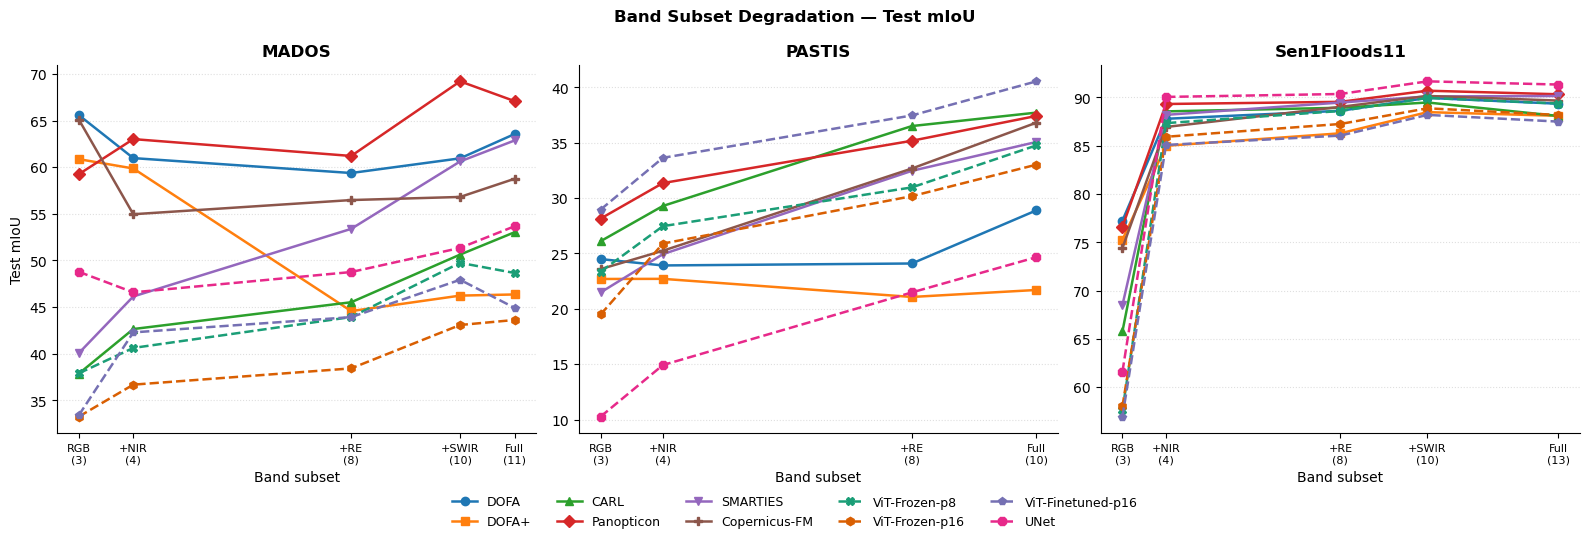

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

FMS       = ["DOFA", "DOFA+", "CARL", "Panopticon", "SMARTIES", "Copernicus-FM"]
BASELINES = ["ViT-Frozen-p8", "ViT-Frozen-p16", "ViT-Finetuned-p16", "UNet"]
PLOT_ORDER = FMS + BASELINES

fm_colors = sns.color_palette("tab10", len(FMS))
bl_colors = sns.color_palette("Dark2",  len(BASELINES))

enc_color  = {e: c for e, c in zip(PLOT_ORDER, fm_colors + bl_colors)}
enc_ls     = {e: "-"  for e in FMS} | {e: "--" for e in BASELINES}
enc_marker = dict(zip(PLOT_ORDER, ["o", "s", "^", "D", "v", "P", "X", "h", "p", "8"]))

XTICK = {
    "MADOS":        {3: "RGB\n(3)", 4: "+NIR\n(4)", 8: "+RE\n(8)", 10: "+SWIR\n(10)", 11: "Full\n(11)"},
    "PASTIS":       {3: "RGB\n(3)", 4: "+NIR\n(4)", 8: "+RE\n(8)", 10: "Full\n(10)"},
    "Sen1Floods11": {3: "RGB\n(3)", 4: "+NIR\n(4)", 8: "+RE\n(8)", 10: "+SWIR\n(10)", 13: "Full\n(13)"},
}

datasets = ["MADOS", "PASTIS", "Sen1Floods11"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, ds in zip(axes, datasets):
    sub     = df_all[df_all["dataset"] == ds]
    present = [e for e in PLOT_ORDER if e in sub["encoder"].unique()]
    xs      = sorted(sub["n_bands"].unique())

    for enc in present:
        row = sub[sub["encoder"] == enc].sort_values("n_bands")
        ax.plot(
            row["n_bands"], row["test_mIoU"],
            color=enc_color[enc], ls=enc_ls[enc],
            marker=enc_marker[enc], ms=6, lw=1.8, label=enc,
        )

    ax.set_title(ds, fontweight="bold")
    ax.set_xlabel("Band subset")
    ax.set_ylabel("Test mIoU" if ds == "MADOS" else "")
    ax.set_xticks(xs)
    ax.set_xticklabels([XTICK[ds].get(x, str(x)) for x in xs], fontsize=8)
    ax.grid(axis="y", ls=":", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

# unified legend in fixed order, drawn below the subplots
legend_handles = {}
for ax in axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        legend_handles[l] = h

ordered_h = [legend_handles[e] for e in PLOT_ORDER if e in legend_handles]
ordered_l = [e                  for e in PLOT_ORDER if e in legend_handles]

fig.legend(ordered_h, ordered_l, loc="lower center", ncol=5,
           fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Band Subset Degradation — Test mIoU", fontweight="bold")
plt.tight_layout()

fig_dir = Path("/dss/dsshome1/08/di54zop/pangaea-bench_dev/notebooks/figures")
fig_dir.mkdir(exist_ok=True)
plt.savefig(fig_dir / "band_degradation_lineplot.pdf", bbox_inches="tight")
plt.show()